In [1]:
!pip install pymoo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 28.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


=== RESULTADOS DA OTIMIZAÇÃO (SOLUÇÕES DE TRADE-OFF) ===

1. Solução de MENOR CUSTO:
   Robôs: 5.00 | Velocidade: 1.00 m/s
   Custo Total: R$ 133.02 mil | Tempo de Ciclo: 63.95 min

2. Solução de MENOR TEMPO (Mais veloz/eficiente):
   Robôs: 16.82 | Velocidade: 3.71 m/s
   Custo Total: R$ 530.30 mil | Tempo de Ciclo: 17.93 min

3. Solução INTERMEDIÁRIA (Equilíbrio / Trade-off ótimo):
   Robôs: 6.88 | Velocidade: 2.81 m/s
   Custo Total: R$ 235.15 mil | Tempo de Ciclo: 31.68 min



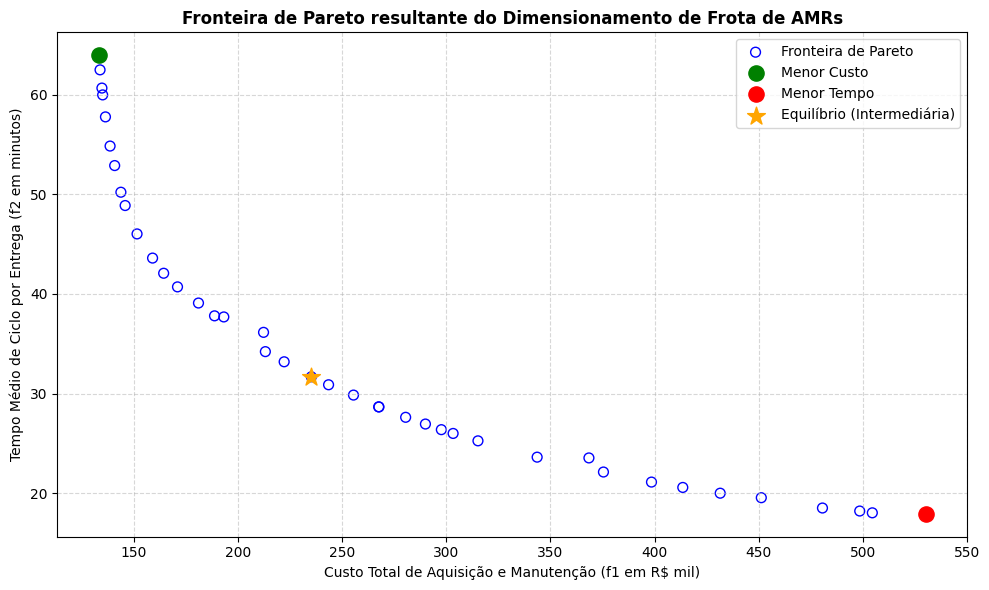

In [7]:
# EXERCÍCIO 7: Dimensionamento de Frota de Robôs de Logística
# Objetivo: Projetar e otimizar a frota de robôs móveis autônomos (AMRs)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class FrotaRobosProblem(ElementwiseProblem):
    def __init__(self):
        # x1: Número de Robôs (5.0 a 50.0), x2: Velocidade de Operação (1.0 a 4.0 m/s)
        # Temos 2 variáveis, 2 objetivos e 1 restrição de desigualdade
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([5.0, 1.0]),
            xu=np.array([50.0, 4.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):
        n_robos, vel = x[0], x[1]

        # Objetivo 1: Custo Total (R$ mil)
        f1_custo = (n_robos * 25.0) + (vel ** 2 * 8.0)

        # Objetivo 2: Tempo Médio de Ciclo (minutos)
        f2_tempo = (120.0 / n_robos) + (40.0 / vel)

        # Restrição de Consumo Energético / Segurança: C(x1, x2) <= 120
        # Reescrevendo na forma g1(x) <= 0: x1 * x2^1.5 - 120 <= 0
        g1 = (n_robos * (vel ** 1.5)) - 120.0

        out["F"] = [f1_custo, f2_tempo]
        out["G"] = [g1]

# 1. Configurar o problema e o algoritmo
problem = FrotaRobosProblem()
algorithm = NSGA2(pop_size=40)

# 2. Executar a otimização por 60 gerações
res = minimize(
    problem,
    algorithm,
    termination=("n_gen", 60),
    seed=42,
    verbose=False
)

# 3. Filtrar e exibir as 3 melhores soluções de trade-off
if res.X is not None and len(res.X) > 0:
    X_opt = res.X
    F_opt = res.F

    # Encontrar índices de interesse
    idx_menor_custo = np.argmin(F_opt[:, 0])
    idx_menor_tempo = np.argmin(F_opt[:, 1])

    # Para a solução intermediária equilibrada, normalizamos os objetivos para encontrar
    # o ponto mais próximo do ideal utópico (0, 0) no espaço normalizado
    f1_min, f1_max = F_opt[:, 0].min(), F_opt[:, 0].max()
    f2_min, f2_max = F_opt[:, 1].min(), F_opt[:, 1].max()

    # Evitar divisão por zero caso o intervalo seja nulo
    f1_norm = (F_opt[:, 0] - f1_min) / (f1_max - f1_min) if f1_max > f1_min else np.zeros(len(F_opt))
    f2_norm = (F_opt[:, 1] - f2_min) / (f2_max - f2_min) if f2_max > f2_min else np.zeros(len(F_opt))

    dist_ideal = np.sqrt(f1_norm**2 + f2_norm**2)
    idx_intermediaria = np.argmin(dist_ideal)

    print("=== RESULTADOS DA OTIMIZAÇÃO (SOLUÇÕES DE TRADE-OFF) ===\n")

    print("1. Solução de MENOR CUSTO:")
    print(f"   Robôs: {X_opt[idx_menor_custo][0]:.2f} | Velocidade: {X_opt[idx_menor_custo][1]:.2f} m/s")
    print(f"   Custo Total: R$ {F_opt[idx_menor_custo][0]:.2f} mil | Tempo de Ciclo: {F_opt[idx_menor_custo][1]:.2f} min\n")

    print("2. Solução de MENOR TEMPO (Mais veloz/eficiente):")
    print(f"   Robôs: {X_opt[idx_menor_tempo][0]:.2f} | Velocidade: {X_opt[idx_menor_tempo][1]:.2f} m/s")
    print(f"   Custo Total: R$ {F_opt[idx_menor_tempo][0]:.2f} mil | Tempo de Ciclo: {F_opt[idx_menor_tempo][1]:.2f} min\n")

    print("3. Solução INTERMEDIÁRIA (Equilíbrio / Trade-off ótimo):")
    print(f"   Robôs: {X_opt[idx_intermediaria][0]:.2f} | Velocidade: {X_opt[idx_intermediaria][1]:.2f} m/s")
    print(f"   Custo Total: R$ {F_opt[idx_intermediaria][0]:.2f} mil | Tempo de Ciclo: {F_opt[idx_intermediaria][1]:.2f} min\n")

    # 4. Gerar e salvar o gráfico da Fronteira de Pareto
    plt.figure(figsize=(10, 6))

    # Plot de todas as soluções da fronteira
    plt.scatter(F_opt[:, 0], F_opt[:, 1], color="blue", facecolors="none", edgecolors="blue", s=50, label="Fronteira de Pareto")

    # Destacar os 3 pontos de interesse
    plt.scatter(F_opt[idx_menor_custo, 0], F_opt[idx_menor_custo, 1], color="green", s=120, zorder=5, label="Menor Custo")
    plt.scatter(F_opt[idx_menor_tempo, 0], F_opt[idx_menor_tempo, 1], color="red", s=120, zorder=5, label="Menor Tempo")
    plt.scatter(F_opt[idx_intermediaria, 0], F_opt[idx_intermediaria, 1], color="orange", marker="*", s=180, zorder=5, label="Equilíbrio (Intermediária)")

    plt.title("Fronteira de Pareto resultante do Dimensionamento de Frota de AMRs", fontsize=12, fontweight="bold")
    plt.xlabel("Custo Total de Aquisição e Manutenção (f1 em R$ mil)", fontsize=10)
    plt.ylabel("Tempo Médio de Ciclo por Entrega (f2 em minutos)", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right", fontsize=10)
    plt.tight_layout()
    plt.savefig("pareto_fronteira_robos.png", dpi=150)
    plt.show()
else:
    print("Erro: Nenhuma solução viável encontrada para traçar os resultados.")